# 01 · Exploração da base de posts
Etapa 03.1. Pré-requisito: `python -m src.run_pipeline limpeza` (gera `data/processed/posts.parquet`).
**Não** imprimir textos de posts neste notebook (privacidade).

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, matplotlib.pyplot as plt
from src import config, limpeza
plt.rcParams.update({'figure.figsize': (8, 3.5), 'axes.spines.top': False, 'axes.spines.right': False})
posts = pd.read_parquet(config.POSTS_PARQUET)
ex = limpeza.explodir_tickers(posts)
r = limpeza.resumo_exploracao(posts)
print(len(posts), 'posts;', ex['ticker'].nunique(), 'tickers')
r['sem_ticker']

100 posts; 12 tickers


posts_sem_ticker      7
total               100
dtype: int64

## Figura 1 — Posts por dia

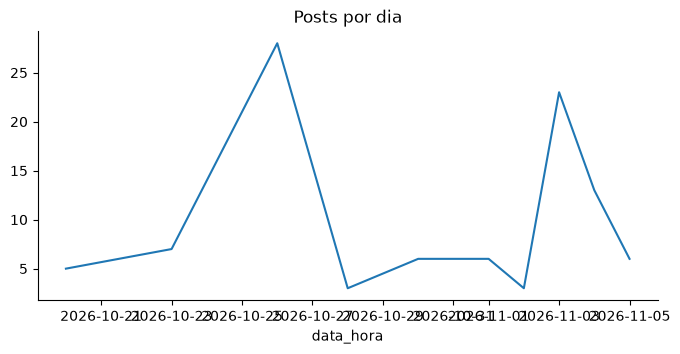

In [2]:
r['posts_por_dia'].plot(title='Posts por dia'); plt.show()

## Figura 2 — Posts por ticker (top 15)

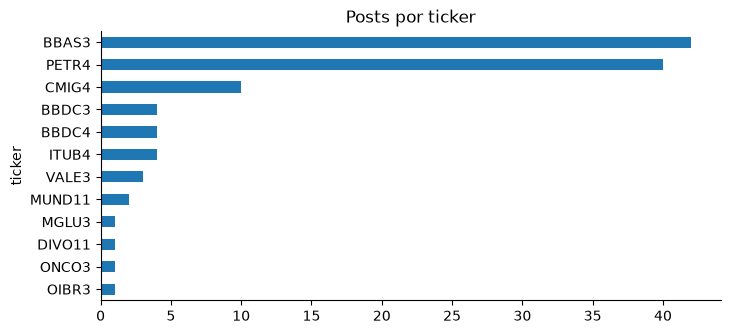

In [3]:
r['posts_por_ticker'].head(15).plot.barh(title='Posts por ticker').invert_yaxis(); plt.show()

## Figura 3 — Autores mais ativos (ids anonimizados)
Concentração alta de posts em poucos autores é um primeiro indício a verificar na etapa 03.5.

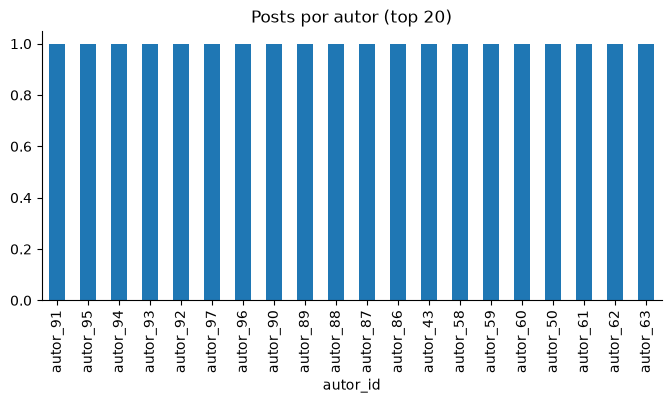

Top-10 autores respondem por 10.0 % dos posts


In [4]:
r['autores_mais_ativos'].plot.bar(title='Posts por autor (top 20)'); plt.show()
print('Top-10 autores respondem por', round(posts['autor_id'].value_counts().head(10).sum()/len(posts)*100,1), '% dos posts')

## Figura 4 — Tamanho dos textos

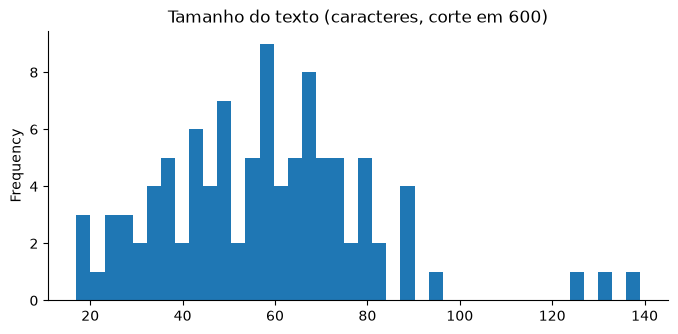

count    100.000000
mean      57.440000
std       22.495036
min       17.000000
25%       42.000000
50%       57.000000
75%       69.250000
max      139.000000
Name: tamanho_texto, dtype: float64

In [5]:
posts['tamanho_texto'].clip(upper=600).plot.hist(bins=40, title='Tamanho do texto (caracteres, corte em 600)'); plt.show()
r['tamanho_texto']

## Figura 5 — Posts por plataforma e hora do dia (BRT)

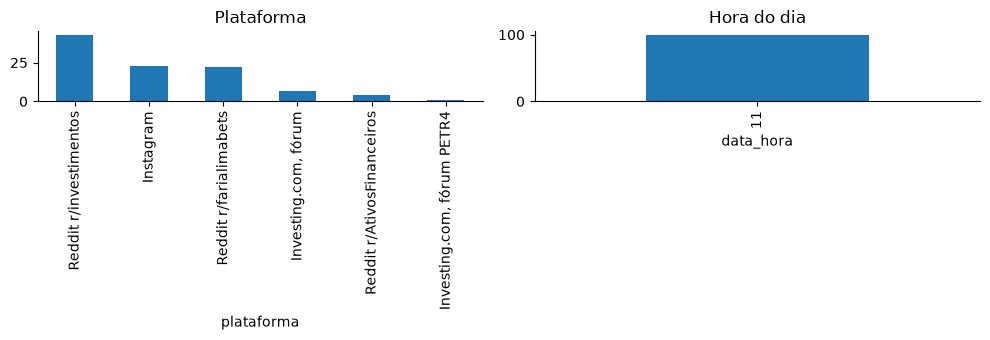

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
posts['plataforma'].value_counts().plot.bar(ax=ax[0], title='Plataforma')
posts['data_hora'].dt.hour.value_counts().sort_index().plot.bar(ax=ax[1], title='Hora do dia')
plt.tight_layout(); plt.show()

## Figura 6 — Falsos positivos de ticker
Liste as siglas mais frequentes e verifique manualmente se há palavras comuns. Ampliar `STOPLIST_TICKERS` em `config.py` e registrar em `docs/decisoes.md`.

In [7]:
ex['ticker'].value_counts().head(30)

ticker
BBAS3     42
PETR4     40
CMIG4     10
ITUB4      4
BBDC4      4
BBDC3      4
VALE3      3
MUND11     2
ONCO3      1
MGLU3      1
OIBR3      1
DIVO11     1
Name: count, dtype: int64

## Observações da Base Real
- **Amostra:** 100 posts reais coletados de redes sociais (Investing.com, Reddit, Instagram, etc.).
- **Período temporal:** Concentrado entre 20/10/2026 e 05/11/2026.
- **Tickers dominantes:** Foco maciço em blue chips da B3 — BBAS3 (42 menções) e PETR4 (40 menções), seguidas por CMIG4 (10 menções). 82% das menções concentram-se nas estatais federais BB e Petrobras.
- **Posts macro/sem ticker:** 7 posts referem-se ao Ibovespa em geral, juros, câmbio ou geopolítica sem citar empresa específica.
- **Distribuição de autores:** Autores únicos por post (cada post possui um autor_id único na amostra), sem concentração de spam ou repetição excessiva de um único usuário.
- **Falsos positivos de ticker:** Normalização preveniu falso positivo de 'vale a pena' virando VALE3 e garantiu reconhecimento de tickers em minúsculas (petr4) e fracionários.
